# T47D CDK variants ± palbociclib — cell-cycle marker gene panel

Standalone notebook that makes the cell-cycle marker gene heatmap from the T47D CDK2/4/6 variant RNA-seq (nf-core/rnaseq, STAR + Salmon).

**Figure produced** (saved to `figures/`): `marker_gene_panel_DMSO_palbo` — DMSO and Palbo as separate panels, each gene z-scored **within** each treatment arm (shows genotype differences under each treatment), with a shared colour scale.
Also `marker_gene_panel_DMSO_palbo_stacked` — the same panels stacked vertically (DMSO on top) with a horizontal colour bar at the bottom.

**To run**
- Keep this notebook next to the `data/` folder, which holds `salmon.merged.gene_tpm.csv` (Salmon gene-level TPM, all genes × 36 samples).
- Python 3 with `pandas`, `numpy`, `matplotlib` (nothing else needed).
- Run all cells top to bottom. The figure is written as SVG + PNG; z-scores are written as CSV to `tables/`.

**Data notes**
- Expression = log2(TPM + 1). If a gene symbol maps to more than one Ensembl ID, the more highly expressed ID is used.
- Samples are named `T47D_<genotype>_<veh|palbo>_<rep>`; `veh` = DMSO.
- The marker genes are a hand-picked panel of canonical cell-cycle genes (`MARKER_GENES`); edit the list to change it.

In [1]:
# ── Imports & style ──────────────────────────────────────────────────────────
%matplotlib inline
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Helvetica if installed, otherwise the closest available sans-serif
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'Nimbus Sans', 'Liberation Sans', 'DejaVu Sans']
plt.rcParams['axes.linewidth'] = 0.3
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'     # keep SVG text editable in Illustrator
plt.rcParams['figure.dpi'] = 110

In [7]:
# ── Paths & settings ─────────────────────────────────────────────────────────
BASE      = Path.cwd()
EXPR_FILE = BASE / 'data' / 'salmon.merged.gene_tpm.csv'
FIG_DIR   = BASE / 'figures'
TABLE_DIR = BASE / 'tables'
FIG_DIR.mkdir(exist_ok=True); TABLE_DIR.mkdir(exist_ok=True)
assert EXPR_FILE.exists(), f'Expression file not found: {EXPR_FILE}'

# Cell-cycle marker genes, top to bottom in the heatmap
MARKER_GENES = ["MKI67", "PCNA",                                   # proliferation
                "CCNE1", "CCNE2", "MCM2", "MCM7", "RRM2", "TYMS",  # G1/S (E2F targets)
                "CCNA2",                                           # S/G2
                "CCNB1", "CCNB2", "CDK1", "TOP2A", "AURKA", "PLK1", # G2/M
                "CDKN1A", "CDKN2A"]                                # CDK inhibitors (p21, p16)

# Genotype order (controls first)
GENOTYPES        = ['ABE_NT', 'CBE_NT', 'CDK2_S261G', 'CDK4_I51V',
                    'CDK6_G53S', 'CDK6_R46W']
CONTROLS         = ['ABE_NT', 'CBE_NT']

TREATMENT_LABELS = {'veh': 'DMSO', 'palbo': 'Palbociclib'}

# Font sizes
FS_TITLE   = 15   # DMSO / Palbociclib panel titles
FS_GENE    = 9    # gene names (y-axis)
FS_XTICK   = 10   # cell-line labels (x-axis)
FS_CBAR    = 12   # colour-bar label
FS_CBTICK  = 11   # colour-bar tick labels


# Cell-line names shown on the x-axis (genotypes not listed use the part after the gene)
DISPLAY_NAMES = {'CDK6_G53S': 'G53S_M54I',
                 'CDK6_R46W': 'R44C_R46W'}


def pretty_label(g):
    """x-axis label: controls on one line ('ABE_NT' -> 'ABE NT'); variants on two lines,
    gene on top, variant below ('CDK2_S261G' -> 'CDK2\\nS261G', 'CDK6_R46W' -> 'CDK6\\nR44C_R46W')."""
    if g in CONTROLS:
        return g.replace('_', ' ')
    gene, variant = str(g).split('_', 1)
    return f'{gene}\n{DISPLAY_NAMES.get(g, variant)}'

In [8]:
# ── Load TPM, build sample metadata and ordering ─────────────────────────────
expr = pd.read_csv(EXPR_FILE, index_col=0)
gene_names = expr.pop('gene_name')

parsed = expr.columns.str.extract(r'^T47D_(?P<genotype>.+)_(?P<treatment>palbo|veh)_\d+$')
metadata = pd.DataFrame({'genotype': parsed['genotype'].values,
                         'treatment': parsed['treatment'].values}, index=expr.columns)
log_expr = np.log2(expr + 1)                       # genes x samples

# genotype (GENOTYPES order) -> treatment (DMSO, Palbo) -> replicate
samples = (metadata.assign(g=metadata['genotype'].map({g: i for i, g in enumerate(GENOTYPES)}),
                           t=metadata['treatment'].map({'veh': 0, 'palbo': 1}))
           .sort_values(['g', 't']).index.tolist())

# symbol -> Ensembl ID (the more highly expressed ID if a symbol is duplicated)
sym_to_id = {}
for gid, gname in gene_names.items():
    if gname in MARKER_GENES and (gname not in sym_to_id or
                                  log_expr.loc[gid].mean() > log_expr.loc[sym_to_id[gname]].mean()):
        sym_to_id[gname] = gid
present = [g for g in MARKER_GENES if g in sym_to_id]
if len(present) < len(MARKER_GENES):
    print('Not found in expression file:', sorted(set(MARKER_GENES) - set(present)))

marker_expr = log_expr.loc[[sym_to_id[g] for g in present], samples]
marker_expr.index = present
print(f'{log_expr.shape[0]} genes x {log_expr.shape[1]} samples loaded; plotting {len(present)} genes x {len(samples)} samples')


def zscore_rows(m):
    return m.sub(m.mean(axis=1), axis=0).div(m.std(axis=1).replace(0, np.nan), axis=0)


def genotype_blocks(genos):
    """[(first_col, last_col, genotype), ...] for runs of the same genotype."""
    blocks, start = [], 0
    for i in range(1, len(genos) + 1):
        if i == len(genos) or genos[i] != genos[start]:
            blocks.append((start, i - 1, genos[start])); start = i
    return blocks

78932 genes x 36 samples loaded; plotting 17 genes x 36 samples


## Marker gene heatmap — DMSO and Palbo panels, z-score within each arm

Each gene is z-scored across the samples of **one** treatment arm only, so each panel shows how the genotypes compare under that treatment. Because each arm is normalized separately, the DMSO → Palbo shift itself is not shown. Both panels share one colour scale. The heavy vertical line separates the NT controls from the variants.

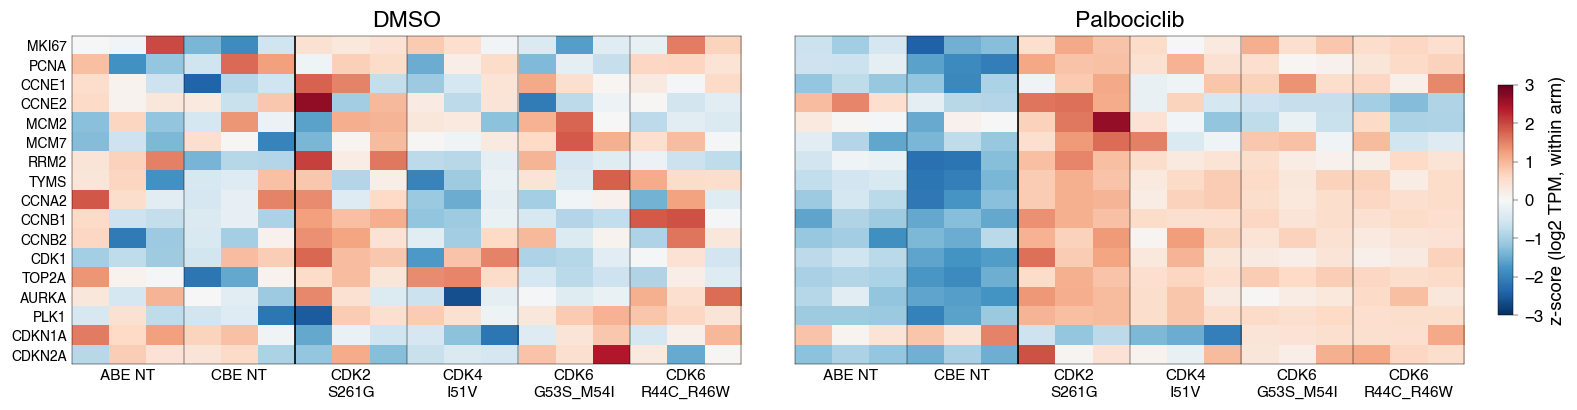

Shared colour scale: ±3.0


In [9]:
arm_z, arm_samples = {}, {}
for trt in ('veh', 'palbo'):
    s = [x for x in samples if metadata.loc[x, 'treatment'] == trt]
    arm_samples[trt] = s
    arm_z[trt] = zscore_rows(marker_expr[s])
    arm_z[trt].to_csv(TABLE_DIR / f'marker_gene_zscore_{TREATMENT_LABELS[trt]}.csv')

vmax = np.ceil(max(np.nanmax(np.abs(z.values)) for z in arm_z.values()) * 2) / 2   # shared, rounded to 0.5
ROW_H, COL_W = 0.14, 0.48   # inches per gene row / per sample column
n_rows, n_cols = len(marker_expr), len(arm_samples['veh'])

fig, axes = plt.subplots(1, 2, figsize=(2 * COL_W * n_cols + 2.4, ROW_H * n_rows + 1.5),
                         gridspec_kw={'wspace': 0.08})
for ax, trt in zip(axes, ('veh', 'palbo')):
    z, s = arm_z[trt], arm_samples[trt]
    im = ax.imshow(z.values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(z.index if ax is axes[0] else [], fontsize=FS_GENE, style='italic')
    ax.tick_params(axis='y', length=0)

    geno = metadata.loc[s, 'genotype'].values
    blocks = genotype_blocks(geno)
    ax.set_xticks([(a + b) / 2 for a, b, _ in blocks])
    ax.set_xticklabels([pretty_label(g) for _, _, g in blocks],
                       fontsize=FS_XTICK, rotation=0, ha='center', va='top', linespacing=1.2)
    ax.tick_params(axis='x', length=0, pad=3)
    for _, b, _ in blocks[:-1]:
        ax.axvline(b + 0.5, color='black', lw=0.3)
    n_ctrl = int(np.isin(geno, CONTROLS).sum())
    if 0 < n_ctrl < len(geno):
        ax.axvline(n_ctrl - 0.5, color='black', lw=1.0)      # NT controls | variants
    for sp in ax.spines.values():
        sp.set_edgecolor('black'); sp.set_linewidth(0.3)
    ax.set_title(TREATMENT_LABELS[trt], fontsize=FS_TITLE, pad=6)

cb = fig.colorbar(im, ax=axes, shrink=0.7, pad=0.02, aspect=15)
cb.set_label('z-score (log2 TPM, within arm)', fontsize=FS_CBAR)
cb.ax.tick_params(labelsize=FS_CBTICK, width=0.3)
cb.outline.set_linewidth(0.3)
plt.savefig(FIG_DIR / 'marker_gene_panel_DMSO_palbo.svg', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'marker_gene_panel_DMSO_palbo.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Shared colour scale: ±{vmax}')

## Stacked version — DMSO above Palbociclib, horizontal colour bar at the bottom

Same within-arm z-scores and shared colour scale as above (run the cell above first). Panels are stacked vertically, columns are slightly narrower, and the colour bar runs horizontally under both panels.

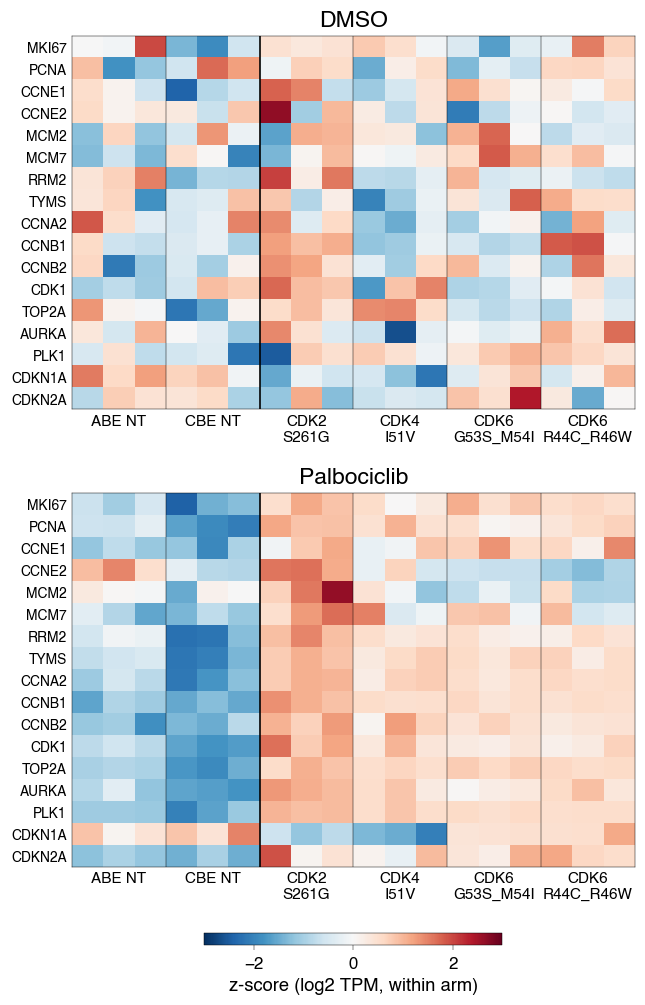

In [12]:
# Stacked layout settings (independent of the side-by-side figure above)
ROW_H_V, COL_W_V = 0.25, 0.3   # inches per gene row / per sample column
CBAR_H = 0.14                   # colour-bar height (inches)

heat_h = ROW_H_V * n_rows
fig_w  = COL_W_V * n_cols + 1.2
# rows: DMSO heatmap | gap for x labels + title | Palbo heatmap | gap for x labels | colour bar
heights = [heat_h, 0.95, heat_h, 0.75, CBAR_H]
fig = plt.figure(figsize=(fig_w, sum(heights) + 0.4))
gs = fig.add_gridspec(5, 3, height_ratios=heights, width_ratios=[0.2, 0.6, 0.2], hspace=0)
axes = [fig.add_subplot(gs[0, :]), fig.add_subplot(gs[2, :])]
cax  = fig.add_subplot(gs[4, 1])

for ax, trt in zip(axes, ('veh', 'palbo')):
    z, s = arm_z[trt], arm_samples[trt]
    im = ax.imshow(z.values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(z.index, fontsize=FS_GENE, style='italic')
    ax.tick_params(axis='y', length=0)

    geno = metadata.loc[s, 'genotype'].values
    blocks = genotype_blocks(geno)
    ax.set_xticks([(a + b) / 2 for a, b, _ in blocks])
    ax.set_xticklabels([pretty_label(g) for _, _, g in blocks],
                       fontsize=FS_XTICK, rotation=0, ha='center', va='top', linespacing=1.2)
    ax.tick_params(axis='x', length=0, pad=3)
    for _, b, _ in blocks[:-1]:
        ax.axvline(b + 0.5, color='black', lw=0.3)
    n_ctrl = int(np.isin(geno, CONTROLS).sum())
    if 0 < n_ctrl < len(geno):
        ax.axvline(n_ctrl - 0.5, color='black', lw=1.0)      # NT controls | variants
    for sp in ax.spines.values():
        sp.set_edgecolor('black'); sp.set_linewidth(0.3)
    ax.set_title(TREATMENT_LABELS[trt], fontsize=FS_TITLE, pad=6)

cb = fig.colorbar(im, cax=cax, orientation='horizontal')
cb.set_label('z-score (log2 TPM, within arm)', fontsize=FS_CBAR)
cb.ax.tick_params(labelsize=FS_CBTICK, width=0.3)
cb.outline.set_linewidth(0.3)
plt.savefig(FIG_DIR / 'marker_gene_panel_DMSO_palbo_stacked.svg', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'marker_gene_panel_DMSO_palbo_stacked.png', dpi=300, bbox_inches='tight')
plt.show()